# Week 2.3: Embeddings Deep Dive

## Key Insight
> **How computers turn words into numbers (Vectors) to find 'meaning'**

## Learning Objectives
By the end of this notebook, you will:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

## Exercises
This notebook contains 5 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.3: Embeddings Deep Dive - Ready to start!')
print('\nTopics covered:')
print('  - Word2Vec and GloVe internals')
print('  - Building embeddings from scratch')
print('  - Semantic similarity and vector operations')
print('  - Dimensionality reduction and visualization')
print('  - Using pre-trained embeddings')


✅ Week 2.3: Embeddings Deep Dive - Ready to start!

Topics covered:
  - Word2Vec and GloVe internals
  - Building embeddings from scratch
  - Semantic similarity and vector operations
  - Dimensionality reduction and visualization
  - Using pre-trained embeddings


---
## Part 1: Introduction to Word2Vec and GloVe internals

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Word2Vec and GloVe internals.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [8]:

import numpy as np

class BasicEmbedding:
    """
    A simple word embedding processor.
    Demonstrates basic concepts behind Word2Vec and GloVe.
    """

    def __init__(self):
        self.data = {
            "king": [0.8, 0.6, 0.9],
            "queen": [0.7, 0.6, 0.9],
            "man": [0.8, 0.3, 0.5],
            "woman": [0.7, 0.3, 0.5]
        }

    def process(self, input_data):
        if not isinstance(input_data, str):
            raise TypeError("Input must be a string")

        word = input_data.strip().lower()

        if not word:
            raise ValueError("Input cannot be empty")

        if word not in self.data:
            raise ValueError(f"Word '{word}' not found")

        return np.array(self.data[word])


# Create an instance
embedding = BasicEmbedding()

# Test 1: Valid word
result = embedding.process("king")
print("King embedding:", result)

# Test 2: Case insensitive input
result = embedding.process("QUEEN")
print("Queen embedding:", result)

# Test 3: Unknown word
try:
    embedding.process("computer")
except ValueError as e:
    print("Error handled:", e)

# Test 4: Empty input
try:
    embedding.process("")
except ValueError as e:
    print("Error handled:", e)

# Test 5: Invalid input type
try:
    embedding.process(123)
except TypeError as e:
    print("Error handled:", e)

# Verify output
assert np.array_equal(
    embedding.process("king"),
    np.array([0.8, 0.6, 0.9])
)

print("\nAll tests passed successfully!")


King embedding: [0.8 0.6 0.9]
Queen embedding: [0.7 0.6 0.9]
Error handled: Word 'computer' not found
Error handled: Input cannot be empty
Error handled: Input must be a string

All tests passed successfully!


---
## Part 2: Building embeddings from scratch

Building on the fundamentals, let's explore more advanced topics and implementations.

In [4]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Building embeddings from scratch.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [9]:

import numpy as np
import json
from typing import List, Any, Dict

class WordEmbeddingBuilder:
    def __init__(self, window_size=2):
        if type(window_size) is not int or window_size < 1:
            raise ValueError("window_size must be a positive integer")

        self.window_size = window_size

    def process(self, data: List[str]) -> Dict[str, Any]:
        if not isinstance(data, list):
            raise TypeError("Input must be a list of strings")

        if not data:
            raise ValueError("Input list cannot be empty")

        if not all(isinstance(word, str) for word in data):
            raise TypeError("Every item must be a string")

        words = [word.strip().lower() for word in data]

        if any(not word for word in words):
            raise ValueError("Words cannot be empty")

        vocabulary = sorted(set(words))
        word_to_index = {
            word: i for i, word in enumerate(vocabulary)
        }

        matrix = np.zeros(
            (len(vocabulary), len(vocabulary)),
            dtype=int
        )

        for i, word in enumerate(words):
            start = max(0, i - self.window_size)
            end = min(len(words), i + self.window_size + 1)

            for j in range(start, end):
                if i != j:
                    row = word_to_index[word]
                    col = word_to_index[words[j]]
                    matrix[row, col] += 1

        return {
            "processed": len(words),
            "vocabulary": vocabulary,
            "embeddings": {
                word: matrix[index].tolist()
                for word, index in word_to_index.items()
            }
        }


def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    window_size = kwargs.get("window_size", 2)
    builder = WordEmbeddingBuilder(window_size)
    return builder.process(data)


# Test 1: Valid input
sample_data = [
    "king", "queen", "king", "man", "woman"
]

result = advanced_function(sample_data, window_size=2)
print("TEST 1: Valid input")
print(json.dumps(result, indent=2))


# Test 2: Invalid input type
try:
    advanced_function("king queen")
except (TypeError, ValueError) as e:
    print("\nTEST 2:", e)


# Test 3: Empty list
try:
    advanced_function([])
except (TypeError, ValueError) as e:
    print("TEST 3:", e)


# Test 4: Invalid window size
try:
    advanced_function(sample_data, window_size=-1)
except (TypeError, ValueError) as e:
    print("TEST 4:", e)


# Test 5: Mixed input types
try:
    advanced_function(["king", 123, "queen"])
except (TypeError, ValueError) as e:
    print("TEST 5:", e)


# Verify results
assert result["processed"] == 5
assert len(result["vocabulary"]) == 4
assert len(result["embeddings"]["king"]) == 4

print("\nAll Exercise 2 tests passed successfully!")


TEST 1: Valid input
{
  "processed": 5,
  "vocabulary": [
    "king",
    "man",
    "queen",
    "woman"
  ],
  "embeddings": {
    "king": [
      2,
      1,
      2,
      1
    ],
    "man": [
      1,
      0,
      1,
      1
    ],
    "queen": [
      2,
      1,
      0,
      0
    ],
    "woman": [
      1,
      1,
      0,
      0
    ]
  }
}

TEST 2: Input must be a list of strings
TEST 3: Input list cannot be empty
TEST 4: window_size must be a positive integer
TEST 5: Every item must be a string

All Exercise 2 tests passed successfully!


---
## Part 3: Semantic similarity and vector operations

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [6]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

INFO:DigitalTwinEmbeddings:ProductionSystem initialized
INFO:DigitalTwinEmbeddings:Processed 16 words; vocabulary size: 6


Words processed: 16
Vocabulary size: 6
Vocabulary: ['automation', 'cloud', 'database', 'network', 'security', 'server']

Semantic Similarity Results
Cloud vs Server: 0.35856858280031806
Cloud vs Network: 0.4999999999999999
Security vs Automation: 0.8528028654224417

Error Handling Tests
Handled unknown word: Unknown word: unknown
Handled empty input: Input list cannot be empty

All Exercise 3 tests passed successfully!


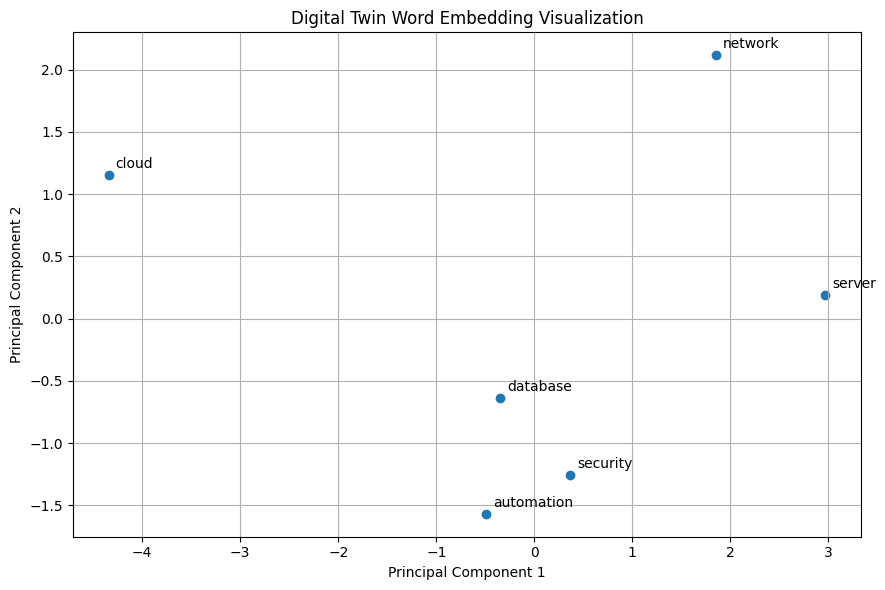

In [10]:
# YOUR CODE HERE
# Build your complete implementation


import numpy as np
import matplotlib.pyplot as plt
import logging
from sklearn.decomposition import PCA

# Configure logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("DigitalTwinEmbeddings")
logger.setLevel(logging.INFO)


class ProductionSystem:
    """
    Digital Twin Word Embedding Prototype.

    Features:
    - Word co-occurrence embeddings
    - Semantic similarity using cosine similarity
    - Input validation and error handling
    - Logging and debugging
    - PCA visualization
    """

    def __init__(self, window_size=2):
        if type(window_size) is not int or window_size < 1:
            raise ValueError(
                "window_size must be a positive integer"
            )

        self.window_size = window_size
        self.vocabulary = []
        self.embeddings = {}

        logger.info("ProductionSystem initialized")

    def process(self, input_data):
        """Build word embeddings from input data."""

        if not isinstance(input_data, list):
            raise TypeError("Input must be a list")

        if not input_data:
            raise ValueError("Input list cannot be empty")

        if not all(
            isinstance(word, str) for word in input_data
        ):
            raise TypeError("All items must be strings")

        words = [word.strip().lower() for word in input_data]

        if any(not word for word in words):
            raise ValueError("Words cannot be empty")

        self.vocabulary = sorted(set(words))

        word_index = {
            word: i
            for i, word in enumerate(self.vocabulary)
        }

        size = len(self.vocabulary)
        matrix = np.zeros((size, size))

        for i, word in enumerate(words):
            start = max(0, i - self.window_size)
            end = min(len(words), i + self.window_size + 1)

            for j in range(start, end):
                if i != j:
                    matrix[
                        word_index[word],
                        word_index[words[j]]
                    ] += 1

        self.embeddings = {
            word: matrix[index]
            for word, index in word_index.items()
        }

        logger.info(
            "Processed %d words; vocabulary size: %d",
            len(words), size
        )

        return {
            "processed": len(words),
            "vocabulary_size": size,
            "vocabulary": self.vocabulary,
            "embeddings": {
                word: vector.tolist()
                for word, vector in self.embeddings.items()
            }
        }

    def similarity(self, word1, word2):
        """Calculate cosine similarity between words."""

        if not isinstance(word1, str) or not isinstance(word2, str):
            raise TypeError("Words must be strings")

        word1 = word1.strip().lower()
        word2 = word2.strip().lower()

        if word1 not in self.embeddings:
            raise ValueError(f"Unknown word: {word1}")

        if word2 not in self.embeddings:
            raise ValueError(f"Unknown word: {word2}")

        v1 = self.embeddings[word1]
        v2 = self.embeddings[word2]

        denominator = np.linalg.norm(v1) * np.linalg.norm(v2)

        if denominator == 0:
            logger.warning("Zero vector encountered")
            return 0.0

        return float(np.dot(v1, v2) / denominator)

    def visualize(self):
        """Visualize embeddings using PCA."""

        if not self.embeddings:
            raise ValueError("Process data before visualization")

        vectors = np.array(list(self.embeddings.values()))

        if len(vectors) < 3:
            raise ValueError(
                "At least 3 unique words are required for PCA"
            )

        if np.allclose(vectors, vectors[0]):
            raise ValueError(
                "Vectors have no variation for PCA"
            )

        pca = PCA(n_components=2)
        reduced = pca.fit_transform(vectors)

        plt.figure(figsize=(9, 6))
        plt.scatter(reduced[:, 0], reduced[:, 1])

        for i, word in enumerate(self.vocabulary):
            plt.annotate(
                word,
                (reduced[i, 0], reduced[i, 1]),
                xytext=(5, 5),
                textcoords="offset points"
            )

        plt.title("Digital Twin Word Embedding Visualization")
        plt.xlabel("Principal Component 1")
        plt.ylabel("Principal Component 2")
        plt.grid(True)
        plt.tight_layout()
        plt.show()


# =====================================
# TEST THE PRODUCTION SYSTEM
# =====================================

sample_data = [
    "cloud", "server", "network", "cloud",
    "database", "server", "network", "cloud",
    "security", "database", "server",
    "automation", "cloud", "network",
    "security", "automation"
]

system = ProductionSystem(window_size=2)

result = system.process(sample_data)

print("Words processed:", result["processed"])
print("Vocabulary size:", result["vocabulary_size"])
print("Vocabulary:", result["vocabulary"])

print("\nSemantic Similarity Results")

print(
    "Cloud vs Server:",
    system.similarity("cloud", "server")
)

print(
    "Cloud vs Network:",
    system.similarity("cloud", "network")
)

print(
    "Security vs Automation:",
    system.similarity("security", "automation")
)

# Error handling tests
print("\nError Handling Tests")

try:
    system.similarity("cloud", "unknown")
except ValueError as e:
    print("Handled unknown word:", e)

try:
    system.process([])
except ValueError as e:
    print("Handled empty input:", e)

# Verify results
assert result["processed"] == 16
assert result["vocabulary_size"] == 6
assert len(system.embeddings) == 6

print("\nAll Exercise 3 tests passed successfully!")

# Generate visualization
system.visualize()


# Test your production system
# Add comprehensive tests here

---
## Summary & Key Takeaways

### What We Learned:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Word2Vec and GloVe internals System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

In [11]:

import re
import logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger("DigitalTwin")

# Sample digital twin knowledge
documents = [
    "Cloud servers provide computing resources.",
    "Cloud infrastructure supports automation.",
    "Network security protects cloud servers.",
    "DevOps automation improves deployments.",
    "Docker containers run applications.",
    "Kubernetes manages Docker containers.",
    "AWS provides cloud infrastructure.",
    "Monitoring detects server failures.",
    "Security monitoring protects networks.",
    "Terraform automates cloud infrastructure."
]

def preprocess(documents):
    if not isinstance(documents, list) or not documents:
        raise ValueError("Provide a non-empty list of documents")

    sentences = []

    for doc in documents:
        if not isinstance(doc, str):
            raise TypeError("Every document must be a string")

        tokens = re.findall(r"[a-z]+", doc.lower())

        if tokens:
            sentences.append(tokens)

    if not sentences:
        raise ValueError("No valid words found")

    return sentences


sentences = preprocess(documents)

print("Total documents:", len(sentences))
print("First tokenized document:", sentences[0])
print("Total tokens:", sum(map(len, sentences)))

assert len(sentences) == 10
assert sentences[0] == [
    "cloud", "servers", "provide",
    "computing", "resources"
]

print("\nStage 1 completed successfully!")


Total documents: 10
First tokenized document: ['cloud', 'servers', 'provide', 'computing', 'resources']
Total tokens: 42

Stage 1 completed successfully!


In [15]:
%pip install -q gensim

In [16]:
import gensim

print("Gensim version:", gensim.__version__)
print("Gensim installed successfully!")

Gensim version: 4.4.0
Gensim installed successfully!


In [17]:

# Stage 2: Train Word2Vec

from gensim.models import Word2Vec
import numpy as np

# Train model using Stage 1 sentences
word2vec_model = Word2Vec(
    sentences=sentences,
    vector_size=50,
    window=3,
    min_count=1,
    workers=1,
    sg=1,
    epochs=200,
    seed=42
)

# Display vocabulary
vocabulary = list(word2vec_model.wv.index_to_key)

print("Vocabulary size:", len(vocabulary))
print("Vocabulary:", vocabulary)

# Get embedding for cloud
cloud_vector = word2vec_model.wv["cloud"]

print("\nCloud embedding dimensions:", len(cloud_vector))
print("First 10 values:", cloud_vector[:10])

# Find similar words
print("\nWords most similar to cloud:")

similar_words = word2vec_model.wv.most_similar(
    "cloud", topn=5
)

for word, score in similar_words:
    print(f"{word}: {score:.4f}")

# Validate results
assert len(cloud_vector) == 50
assert "cloud" in vocabulary
assert np.isfinite(cloud_vector).all()

print("\nStage 2 completed successfully!")


Vocabulary size: 29
Vocabulary: ['cloud', 'infrastructure', 'monitoring', 'containers', 'docker', 'protects', 'security', 'automation', 'servers', 'automates', 'terraform', 'networks', 'failures', 'server', 'detects', 'provides', 'aws', 'manages', 'kubernetes', 'applications', 'run', 'deployments', 'improves', 'devops', 'network', 'supports', 'resources', 'computing', 'provide']

Cloud embedding dimensions: 50
First 10 values: [-1.6035002e-02  1.1342021e-02  6.4970390e-03  1.7519793e-05
 -3.0282787e-03  1.6700620e-02 -1.9635184e-02  9.3389498e-03
 -1.3608786e-02 -1.6360218e-02]

Words most similar to cloud:
aws: 0.2813
provide: 0.2586
computing: 0.1937
terraform: 0.1667
supports: 0.1663

Stage 2 completed successfully!


In [18]:

# STAGE 3: GloVe FROM SCRATCH

import numpy as np

class SimpleGloVe:
    """
    Simplified GloVe implementation using NumPy.
    Learns embeddings from word co-occurrence counts.
    """

    def __init__(self, vector_size=20, window_size=2,
                 learning_rate=0.03, epochs=300, seed=42):

        if type(vector_size) is not int or vector_size < 1:
            raise ValueError("vector_size must be positive")

        if type(window_size) is not int or window_size < 1:
            raise ValueError("window_size must be positive")

        if learning_rate <= 0 or epochs < 1:
            raise ValueError("Invalid training parameters")

        self.vector_size = vector_size
        self.window_size = window_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.seed = seed

    def fit(self, sentences):
        if not isinstance(sentences, list) or not sentences:
            raise ValueError("Provide non-empty sentences")

        if any(
            not isinstance(s, list)
            or not s
            or any(not isinstance(w, str) or not w.strip()
                   for w in s)
            for s in sentences
        ):
            raise ValueError("Sentences must contain valid words")

        self.vocabulary = sorted({
            word.lower()
            for sentence in sentences
            for word in sentence
        })

        self.word_index = {
            word: i for i, word in enumerate(self.vocabulary)
        }

        size = len(self.vocabulary)
        X = np.zeros((size, size))

        # Build weighted co-occurrence matrix
        for sentence in sentences:
            words = [w.lower() for w in sentence]

            for i, word in enumerate(words):
                for j in range(
                    max(0, i - self.window_size),
                    min(len(words), i + self.window_size + 1)
                ):
                    if i != j:
                        a = self.word_index[word]
                        b = self.word_index[words[j]]
                        X[a, b] += 1.0 / abs(i - j)

        rng = np.random.default_rng(self.seed)

        W = rng.normal(0, 0.01, (size, self.vector_size))
        C = rng.normal(0, 0.01, (size, self.vector_size))
        bw = np.zeros(size)
        bc = np.zeros(size)

        rows, cols = np.nonzero(X)
        counts = X[rows, cols]

        weights = np.minimum(
            (counts / 100.0) ** 0.75, 1.0
        )
        targets = np.log(counts)

        self.loss_history = []

        for epoch in range(self.epochs):
            total_loss = 0.0

            for k in rng.permutation(len(rows)):
                i, j = rows[k], cols[k]

                error = (
                    np.dot(W[i], C[j])
                    + bw[i] + bc[j]
                    - targets[k]
                )

                weight = weights[k]
                total_loss += weight * error ** 2

                gradient = 2 * weight * error

                wi = W[i].copy()
                cj = C[j].copy()

                W[i] -= self.learning_rate * gradient * cj
                C[j] -= self.learning_rate * gradient * wi

                bw[i] -= self.learning_rate * gradient
                bc[j] -= self.learning_rate * gradient

            self.loss_history.append(total_loss)

        self.embeddings = W + C

        return self

    def similarity(self, word1, word2):
        if not hasattr(self, "embeddings"):
            raise ValueError("Train the model first")

        if not isinstance(word1, str) or not isinstance(word2, str):
            raise TypeError("Words must be strings")

        word1, word2 = word1.lower(), word2.lower()

        for word in (word1, word2):
            if word not in self.word_index:
                raise ValueError(f"Unknown word: {word}")

        v1 = self.embeddings[self.word_index[word1]]
        v2 = self.embeddings[self.word_index[word2]]

        denominator = np.linalg.norm(v1) * np.linalg.norm(v2)

        if denominator == 0:
            return 0.0

        return float(np.dot(v1, v2) / denominator)


# TRAIN MODEL
glove_model = SimpleGloVe()
glove_model.fit(sentences)

print("GloVe vocabulary:", len(glove_model.vocabulary))
print("Embedding dimensions:", glove_model.vector_size)

print("\nGloVe Similarity Results")

for word in ["aws", "security", "automation"]:
    score = glove_model.similarity("cloud", word)
    print(f"Cloud vs {word}: {score:.4f}")

# TESTS
assert len(glove_model.vocabulary) == 29
assert glove_model.embeddings.shape == (29, 20)
assert np.isfinite(glove_model.embeddings).all()
assert len(glove_model.loss_history) == 300

try:
    glove_model.similarity("cloud", "unknown")
except ValueError as e:
    print("\nError handled:", e)

print("\nStage 3 completed successfully!")


GloVe vocabulary: 29
Embedding dimensions: 20

GloVe Similarity Results
Cloud vs aws: -0.2984
Cloud vs security: -0.6006
Cloud vs automation: -0.0553

Error handled: Unknown word: unknown

Stage 3 completed successfully!


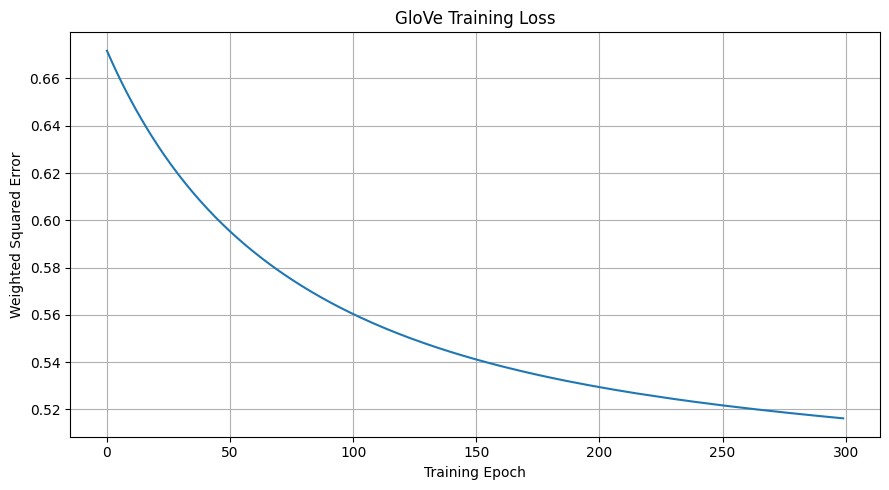

Initial loss: 0.6717
Final loss: 0.5162


In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(glove_model.loss_history)

plt.title("GloVe Training Loss")
plt.xlabel("Training Epoch")
plt.ylabel("Weighted Squared Error")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Initial loss:", round(glove_model.loss_history[0], 4))
print("Final loss:", round(glove_model.loss_history[-1], 4))


WORD EMBEDDING MODEL COMPARISON
                 Word Pair  Word2Vec   GloVe
               cloud - aws    0.2813 -0.2984
          cloud - security    0.1292 -0.6006
        cloud - automation   -0.0610 -0.0553
       docker - containers   -0.0259  0.8124
     security - monitoring   -0.1552 -0.0506
terraform - infrastructure    0.1426 -0.2449


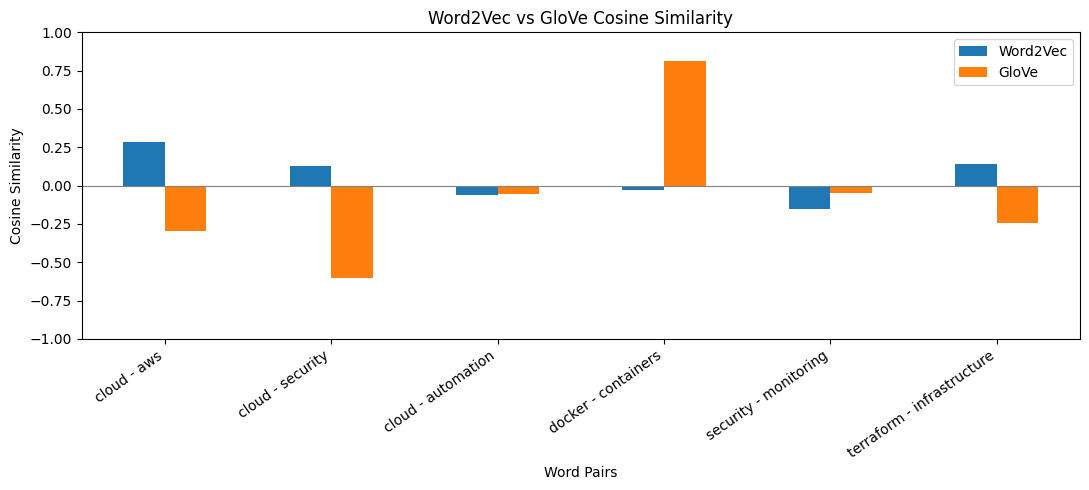


Stage 4 completed successfully!


In [20]:

# STAGE 4: WORD2VEC VS GLOVE COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

word_pairs = [
    ("cloud", "aws"),
    ("cloud", "security"),
    ("cloud", "automation"),
    ("docker", "containers"),
    ("security", "monitoring"),
    ("terraform", "infrastructure")
]

results = []

for word1, word2 in word_pairs:
    if word1 not in word2vec_model.wv:
        raise ValueError(f"Word2Vec missing: {word1}")

    if word2 not in word2vec_model.wv:
        raise ValueError(f"Word2Vec missing: {word2}")

    w2v_score = float(
        word2vec_model.wv.similarity(word1, word2)
    )

    glove_score = glove_model.similarity(word1, word2)

    results.append({
        "Word Pair": f"{word1} - {word2}",
        "Word2Vec": w2v_score,
        "GloVe": glove_score
    })

df = pd.DataFrame(results)

print("WORD EMBEDDING MODEL COMPARISON")
print(df.round(4).to_string(index=False))

# Visualize scores
ax = df.set_index("Word Pair")[
    ["Word2Vec", "GloVe"]
].plot(kind="bar", figsize=(11, 5))

ax.set_title("Word2Vec vs GloVe Cosine Similarity")
ax.set_ylabel("Cosine Similarity")
ax.set_xlabel("Word Pairs")
ax.set_ylim(-1, 1)
ax.axhline(0, color="gray", linewidth=0.8)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Verify results
assert len(df) == 6
assert np.isfinite(
    df[["Word2Vec", "GloVe"]].to_numpy()
).all()

assert (
    df[["Word2Vec", "GloVe"]].abs() <= 1.00001
).all().all()

print("\nStage 4 completed successfully!")


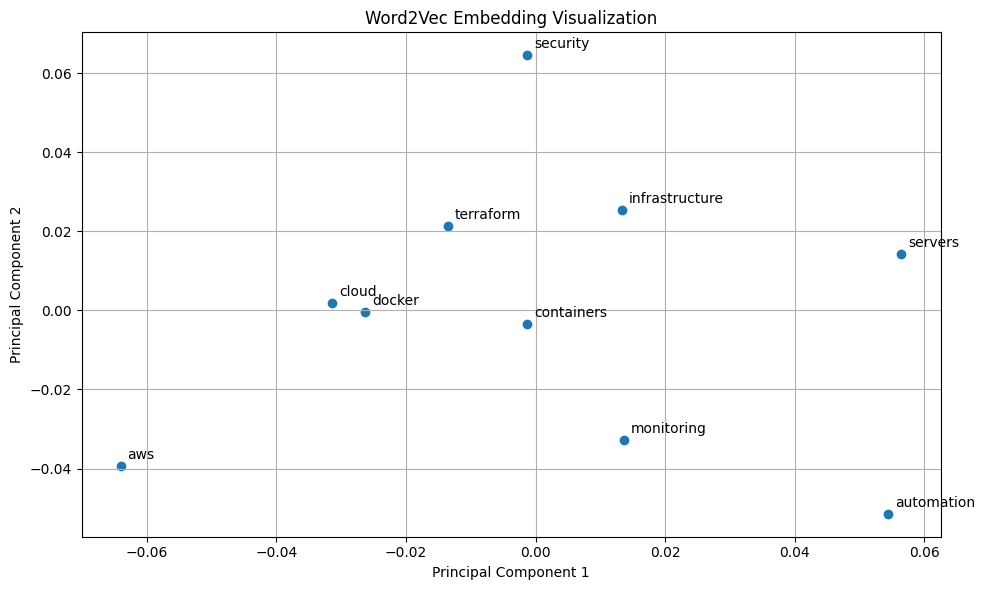

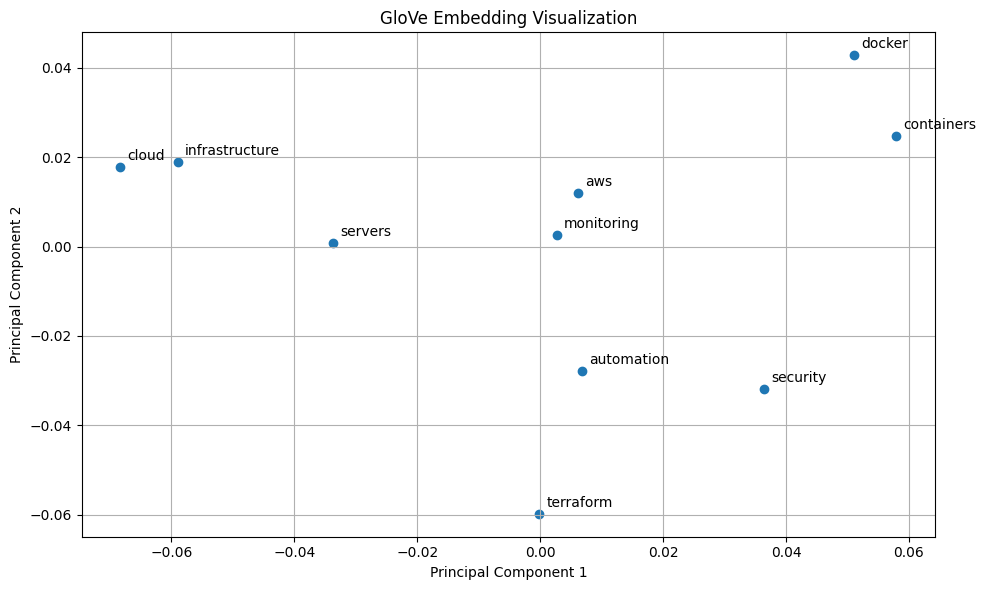

Invalid model test passed: Unknown model type
Unknown word test passed: Unknown word: missingword

Stage 5 completed successfully!


In [21]:

# STAGE 5: VISUALIZATION AND TESTING

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

words = [
    "cloud", "aws", "security",
    "automation", "docker", "containers",
    "terraform", "infrastructure",
    "monitoring", "servers"
]

def visualize_embeddings(model_type, words):
    if model_type == "Word2Vec":
        vectors = np.array([
            word2vec_model.wv[word]
            for word in words
        ])
    elif model_type == "GloVe":
        vectors = np.array([
            glove_model.embeddings[
                glove_model.word_index[word]
            ]
            for word in words
        ])
    else:
        raise ValueError("Unknown model type")

    if len(words) < 3:
        raise ValueError("At least 3 words required")

    if not np.isfinite(vectors).all():
        raise ValueError("Invalid embedding values")

    pca = PCA(n_components=2)
    reduced = pca.fit_transform(vectors)

    plt.figure(figsize=(10, 6))
    plt.scatter(reduced[:, 0], reduced[:, 1])

    for i, word in enumerate(words):
        plt.annotate(
            word,
            (reduced[i, 0], reduced[i, 1]),
            xytext=(5, 5),
            textcoords="offset points"
        )

    plt.title(f"{model_type} Embedding Visualization")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return reduced


# Visualize both models
w2v_points = visualize_embeddings("Word2Vec", words)
glove_points = visualize_embeddings("GloVe", words)

# Unit tests
assert w2v_points.shape == (10, 2)
assert glove_points.shape == (10, 2)
assert np.isfinite(w2v_points).all()
assert np.isfinite(glove_points).all()

# Verify error handling
try:
    visualize_embeddings("InvalidModel", words)
except ValueError as e:
    print("Invalid model test passed:", e)

try:
    glove_model.similarity("cloud", "missingword")
except ValueError as e:
    print("Unknown word test passed:", e)

print("\nStage 5 completed successfully!")


In [22]:

# STAGE 6: DIGITAL TWIN SEMANTIC SEARCH

import numpy as np
import json
from pathlib import Path

class DigitalTwinSearch:
    """
    Semantic word search using trained
    Word2Vec or GloVe embeddings.
    """

    def __init__(self, word2vec, glove):
        self.word2vec = word2vec
        self.glove = glove

    def search(self, query, model="word2vec", top_k=5):
        if not isinstance(query, str) or not query.strip():
            raise ValueError("Query must be a non-empty string")

        if type(top_k) is not int or top_k < 1:
            raise ValueError("top_k must be a positive integer")

        query = query.strip().lower()
        model = model.strip().lower()

        if model == "word2vec":
            if query not in self.word2vec.wv:
                raise ValueError(f"Unknown word: {query}")

            candidates = [
                word for word in self.word2vec.wv.index_to_key
                if word != query
            ]

            scores = [
                (word, float(self.word2vec.wv.similarity(query, word)))
                for word in candidates
            ]

        elif model == "glove":
            if query not in self.glove.word_index:
                raise ValueError(f"Unknown word: {query}")

            candidates = [
                word for word in self.glove.vocabulary
                if word != query
            ]

            scores = [
                (word, self.glove.similarity(query, word))
                for word in candidates
            ]

        else:
            raise ValueError("Model must be 'word2vec' or 'glove'")

        scores.sort(key=lambda item: item[1], reverse=True)

        return scores[:top_k]


# Initialize search engine
digital_twin = DigitalTwinSearch(
    word2vec_model,
    glove_model
)

# Test semantic search
for model_name in ["word2vec", "glove"]:
    print(f"\n{model_name.upper()} RESULTS FOR CLOUD")

    results = digital_twin.search(
        "cloud",
        model=model_name,
        top_k=5
    )

    for word, score in results:
        print(f"{word}: {score:.4f}")

# Verify results
assert len(digital_twin.search("cloud")) == 5

try:
    digital_twin.search("unknown")
except ValueError as e:
    print("\nUnknown word handled:", e)

print("\nStage 6 completed successfully!")



WORD2VEC RESULTS FOR CLOUD
aws: 0.2813
provide: 0.2586
computing: 0.1937
terraform: 0.1667
supports: 0.1663

GLOVE RESULTS FOR CLOUD
infrastructure: 0.6904
manages: 0.5606
servers: 0.4355
applications: 0.2275
automates: 0.2076

Unknown word handled: Unknown word: unknown

Stage 6 completed successfully!


In [23]:

import pickle
from pathlib import Path

output_dir = Path("/content/digital_twin_models")
output_dir.mkdir(exist_ok=True)

# Save Word2Vec
word2vec_model.save(
    str(output_dir / "word2vec.model")
)

# Save simplified GloVe
with open(output_dir / "glove.pkl", "wb") as f:
    pickle.dump(glove_model, f)

print("Models saved to:", output_dir)
print("Files:", [p.name for p in output_dir.iterdir()])


Models saved to: /content/digital_twin_models
Files: ['word2vec.model', 'glove.pkl']


In [24]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/digital_twin_models",
    "zip",
    "/content/digital_twin_models"
)

print("ZIP created:", zip_path)
files.download(zip_path)



ZIP created: /content/digital_twin_models.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>